# Whiff Prediction

## Imports and Data Preparation

In [1]:
import pandas as pd
from pathlib import Path

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [2]:
csv_path = Path("mlb_pitches_2026.csv")
if not csv_path.exists():
    csv_path = Path("mlb_pitches_2026.csv")

pitches = pd.read_csv(csv_path)
pitches.shape

(716792, 119)

## Feature Selection

### Creating `is_whiff` Column

In [3]:
contact_events = {
    "foul",
    "foul_tip",
    "foul_bunt",
    "bunt_foul_tip",
    "hit_into_play",
}
whiff_events = {
    "swinging_strike",
    "swinging_strike_blocked",
    "missed_bunt",
    "swinging_pitchout",
}
pitches["is_swing"] = pitches["description"].isin(contact_events | whiff_events)
pitches["is_whiff"] = pitches["description"].isin(whiff_events)
pitches[["description", "is_swing", "is_whiff"]].head(5)

,description,is_swing,is_whiff
0,swinging_strike,True,True
1,swinging_strike,True,True
2,called_strike,False,False
3,hit_into_play,True,False
4,hit_into_play,True,False


## Exploratory Data Analysis

To match our baseline model, this section uses all pitches, labeling each as a whiff or non-whiff. A whiff rate is the number of swinging strikes divided by the number of pitches. We examine how whiff rate changes with pitch type, release speed, pitch location, and the ball–strike count to guide feature selection.

In [4]:
import numpy as np
import matplotlib.pyplot as plt

eda = pitches.copy()
eda["is_whiff"] = eda["is_whiff"].astype(int)
print(f"Pitches: {len(eda):,}; overall whiff rate: {eda['is_whiff'].mean():.3f}")

Pitches: 716,792; overall whiff rate: 0.109


### Whiff Rate by Pitch Type

Pitch types with fewer than 1,000 pitches are excluded so rates are not driven by small samples. The red dashed line marks the overall whiff rate.

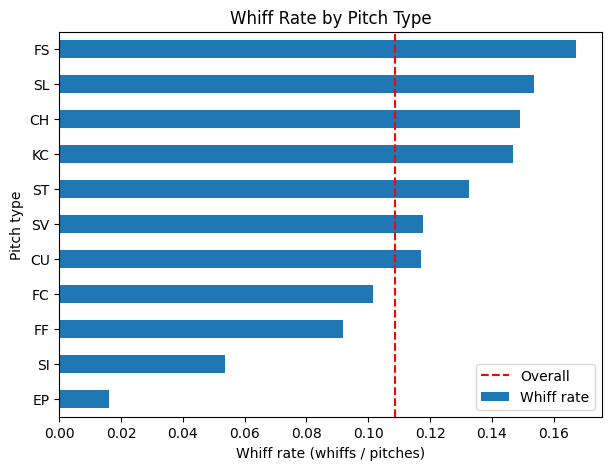

In [5]:
by_type = (eda.groupby("pitch_type")["is_whiff"]
           .agg(whiff_rate="mean", n="size")
           .query("n >= 1000")
           .sort_values("whiff_rate"))

ax = by_type["whiff_rate"].plot(kind="barh", figsize=(7, 5), label="Whiff rate")
ax.axvline(eda["is_whiff"].mean(), color="red", linestyle="--", label="Overall")
ax.set_xlabel("Whiff rate (whiffs / pitches)")
ax.set_ylabel("Pitch type")
ax.set_title("Whiff Rate by Pitch Type")
ax.legend()
plt.show()

### Whiff Rate vs. Release Speed

Speed is plotted separately for the five most common pitch types because pitch types differ systematically in speed; pooling them could hide or reverse the relationship within each type. Speed bins with fewer than 200 pitches are omitted.

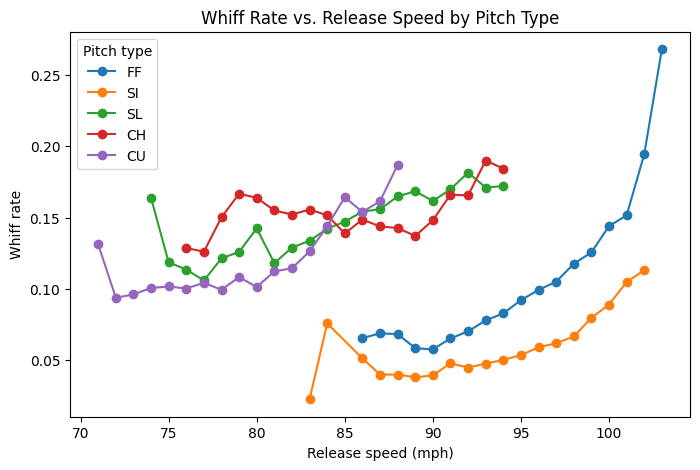

In [6]:
main_types = ["FF", "SI", "SL", "CH", "CU"]
subset = eda[eda["pitch_type"].isin(main_types)].copy()
subset["speed_bin"] = subset["release_speed"].round()

fig, ax = plt.subplots(figsize=(8, 5))
for pitch in main_types:
    rates = subset[subset["pitch_type"] == pitch].groupby("speed_bin")["is_whiff"].agg(["mean", "size"])
    rates = rates[rates["size"] >= 200]
    ax.plot(rates.index, rates["mean"], marker="o", label=pitch)
ax.set_xlabel("Release speed (mph)")
ax.set_ylabel("Whiff rate")
ax.set_title("Whiff Rate vs. Release Speed by Pitch Type")
ax.legend(title="Pitch type")
plt.show()

### Whiff Rate by Pitch Location

Each square shows the whiff rate for pitches at that plate location, from the catcher's view. Squares with fewer than 50 pitches are left blank. The black rectangle is an approximate strike zone.

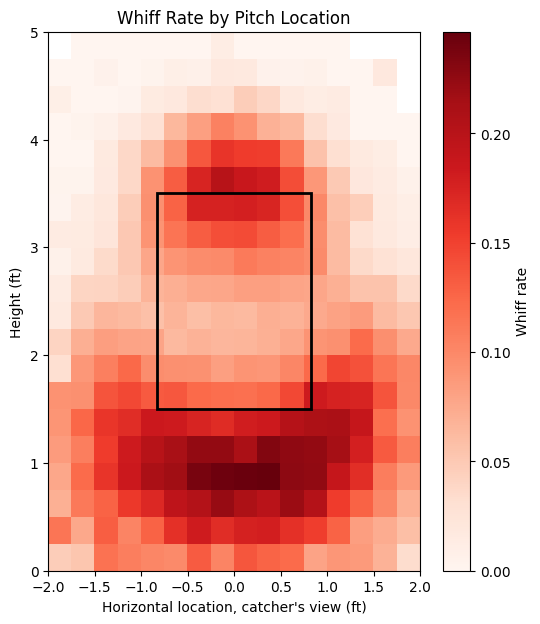

In [7]:
loc = eda.dropna(subset=["plate_x", "plate_z"]).copy()
loc["x_bin"] = pd.cut(loc["plate_x"], bins=np.arange(-2, 2.01, 0.25))
loc["z_bin"] = pd.cut(loc["plate_z"], bins=np.arange(0, 5.01, 0.25))

grid = loc.pivot_table(index="z_bin", columns="x_bin", values="is_whiff",
                       aggfunc="mean", observed=False)
counts = loc.pivot_table(index="z_bin", columns="x_bin", values="is_whiff",
                         aggfunc="size", observed=False)
grid = grid.where(counts >= 50)

fig, ax = plt.subplots(figsize=(6, 7))
im = ax.imshow(grid, origin="lower", extent=[-2, 2, 0, 5], cmap="Reds", aspect="auto")
ax.add_patch(plt.Rectangle((-0.83, 1.5), 1.66, 2.0, fill=False, color="black", lw=2))
fig.colorbar(im, label="Whiff rate")
ax.set_xlabel("Horizontal location, catcher's view (ft)")
ax.set_ylabel("Height (ft)")
ax.set_title("Whiff Rate by Pitch Location")
plt.show()

### Whiff Rate by Ball–Strike Count

Each cell shows the whiff rate for pitches thrown in that count.

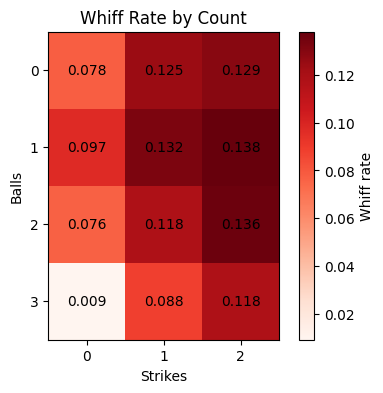

In [8]:
count_grid = eda[eda["balls"] <= 3].pivot_table(
    index="balls", columns="strikes", values="is_whiff", aggfunc="mean")

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(count_grid, cmap="Reds")
for i in range(count_grid.shape[0]):
    for j in range(count_grid.shape[1]):
        ax.text(j, i, f"{count_grid.iloc[i, j]:.3f}", ha="center", va="center")
ax.set_xticks(range(count_grid.shape[1]), count_grid.columns)
ax.set_yticks(range(count_grid.shape[0]), count_grid.index)
ax.set_xlabel("Strikes")
ax.set_ylabel("Balls")
ax.set_title("Whiff Rate by Count")
fig.colorbar(im, label="Whiff rate")
plt.show()

### EDA Takeaways

- **Pitch type:** Whiff rates differ sharply by pitch type. Splitters (FS, about 0.17), sliders (SL), changeups (CH), and knuckle curves (KC) (about 0.15 each) are well above the overall rate of 0.109, while four-seam fastballs (FF, about 0.09) and sinkers (SI, about 0.05) are below it. Breaking and offspeed pitches generally produce more whiffs than fastballs.
- **Speed:** Whiff rate rises with velocity within every main pitch type. The effect is strongest for four-seamers, which go from about 0.07 below 90 mph to about 0.27 at 103 mph. Sinkers rise from about 0.04 to about 0.11. Because the size of the speed effect depends on pitch type, a speed × pitch type interaction may be useful.
- **Location:** Whiffs concentrate just below the strike zone (about 0.5–1.5 ft high) and near the top of the zone. Pitches far outside the zone have whiff rates near zero, likely because batters rarely swing at them, while pitches in the middle of the zone are often hit. Because whiff rate per pitch combines whether the batter swings and whether they miss, location matters in a nonlinear way. `plate_x` and `plate_z` are not in the current model and are strong candidates to add.
- **Count:** Whiff rate rises with strikes, from about 0.08–0.10 with 0 strikes to about 0.12–0.13 with 2 strikes. It is near zero in 3–0 counts (0.009), when batters usually take the pitch. Counts affect whiff rate in a nonlinear way, so treating the count as a category may work better than separate numeric balls and strikes.

These patterns support keeping pitch type, speed, and count, and motivate adding plate location as a predictor.